In [1]:
# Objective: Perform exploratory data analysis on unemployment data to uncover regional
# and temporal trends, with a focus on the impact of the COVID-19 pandemic on
# unemployment rates in India.

In [ ]:
# Import required Libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
#Data Loading
df = pd.read_csv("Unemployment in India.csv")
df.head()

In [7]:
#Shape Inspection
df.shape



Index(['Region', ' Date', ' Frequency', ' Estimated Unemployment Rate (%)',
       ' Estimated Employed', ' Estimated Labour Participation Rate (%)',
       'Area'],
      dtype='object')

In [8]:
df.columns

Index(['Region', ' Date', ' Frequency', ' Estimated Unemployment Rate (%)',
       ' Estimated Employed', ' Estimated Labour Participation Rate (%)',
       'Area'],
      dtype='object')

In [9]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 7 columns):
 #   Column                                    Non-Null Count  Dtype  
---  ------                                    --------------  -----  
 0   Region                                    740 non-null    object 
 1    Date                                     740 non-null    object 
 2    Frequency                                740 non-null    object 
 3    Estimated Unemployment Rate (%)          740 non-null    float64
 4    Estimated Employed                       740 non-null    float64
 5    Estimated Labour Participation Rate (%)  740 non-null    float64
 6   Area                                      740 non-null    object 
dtypes: float64(3), object(4)
memory usage: 42.1+ KB


In [10]:
# Null Value Check
df.isnull().sum()

Region                                      28
 Date                                       28
 Frequency                                  28
 Estimated Unemployment Rate (%)            28
 Estimated Employed                         28
 Estimated Labour Participation Rate (%)    28
Area                                        28
dtype: int64

In [12]:
# Null percentage
(df.isnull().sum() / len(df) * 100).round(2)

Region                                      3.65
 Date                                       3.65
 Frequency                                  3.65
 Estimated Unemployment Rate (%)            3.65
 Estimated Employed                         3.65
 Estimated Labour Participation Rate (%)    3.65
Area                                        3.65
dtype: float64

In [13]:
# Type Conversion
df.columns = df.columns.str.strip()

In [14]:
# Date → datetime
df["Date"] = pd.to_datetime(
    df["Date"],
    dayfirst=True,
    errors="coerce"
)

In [15]:
# Numerical columns → numeric
numeric_columns = [
    "Estimated Unemployment Rate (%)",
    "Estimated Employed",
    "Estimated Labour Participation Rate (%)"
]

for col in numeric_columns:
    df[col] = pd.to_numeric(df[col], errors="coerce")

In [16]:
df.dtypes

Region                                             object
Date                                       datetime64[ns]
Frequency                                          object
Estimated Unemployment Rate (%)                   float64
Estimated Employed                                float64
Estimated Labour Participation Rate (%)           float64
Area                                               object
dtype: object

df.isnull().sum()

EDA

In [19]:
# Region-wise Average Unemployment
region_avg = (
    df.groupby("Region")["Estimated Unemployment Rate (%)"]
      .mean()
      .sort_values(ascending=False)
)

region_avg

Region
Tripura             28.350357
Haryana             26.283214
Jharkhand           20.585000
Bihar               18.918214
Himachal Pradesh    18.540357
Delhi               16.495357
Jammu & Kashmir     16.188571
Chandigarh          15.991667
Rajasthan           14.058214
Uttar Pradesh       12.551429
Punjab              12.031071
Puducherry          10.215000
Kerala              10.123929
Tamil Nadu           9.284286
Goa                  9.274167
Chhattisgarh         9.240357
West Bengal          8.124643
Telangana            7.737857
Maharashtra          7.557500
Andhra Pradesh       7.477143
Madhya Pradesh       7.406429
Sikkim               7.249412
Karnataka            6.676071
Gujarat              6.663929
Uttarakhand          6.582963
Assam                6.428077
Odisha               5.657857
Meghalaya            4.798889
Name: Estimated Unemployment Rate (%), dtype: float64

In [20]:
top_10 = region_avg.head(10)
top_10

Region
Tripura             28.350357
Haryana             26.283214
Jharkhand           20.585000
Bihar               18.918214
Himachal Pradesh    18.540357
Delhi               16.495357
Jammu & Kashmir     16.188571
Chandigarh          15.991667
Rajasthan           14.058214
Uttar Pradesh       12.551429
Name: Estimated Unemployment Rate (%), dtype: float64

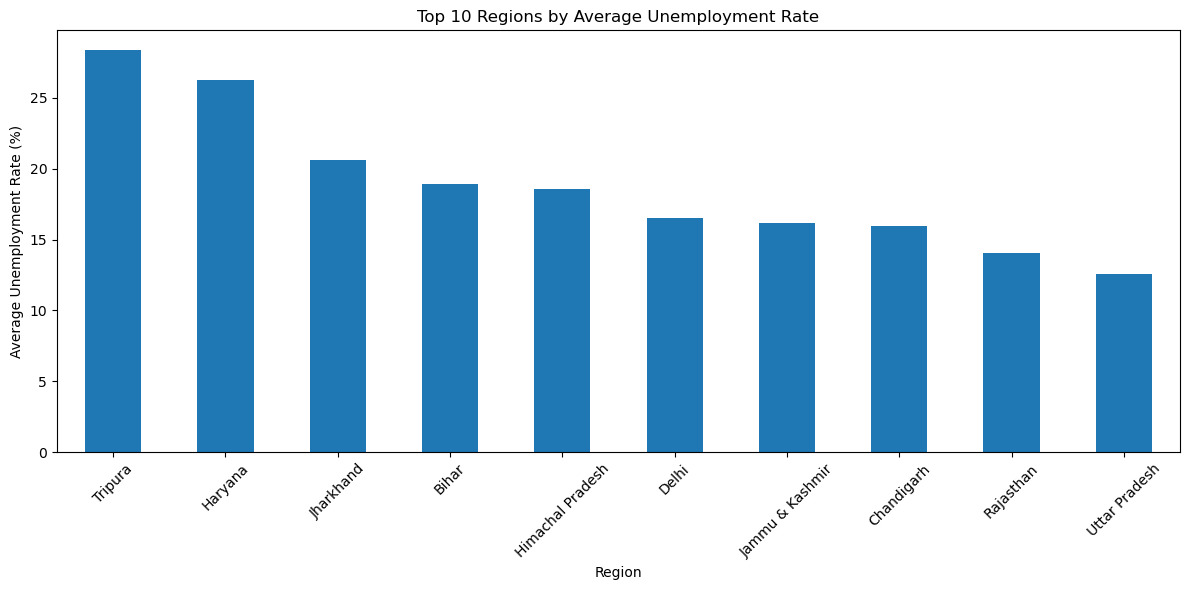

In [21]:
# Visualization 
plt.figure(figsize=(12, 6))

top_10.plot(kind="bar")

plt.title("Top 10 Regions by Average Unemployment Rate")
plt.xlabel("Region")
plt.ylabel("Average Unemployment Rate (%)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


In [27]:
# Month Wise Trend 
monthly_avg = (
    df.groupby(df["Date"].dt.to_period("M"))
      ["Estimated Unemployment Rate (%)"]
      .mean()
)

monthly_avg.index = monthly_avg.index.to_timestamp()

monthly_avg

Date
2019-05-01     8.874259
2019-06-01     9.303333
2019-07-01     9.033889
2019-08-01     9.637925
2019-09-01     9.051731
2019-10-01     9.900909
2019-11-01     9.868364
2019-12-01     9.497358
2020-01-01     9.950755
2020-02-01     9.964717
2020-03-01    10.700577
2020-04-01    23.641569
2020-05-01    24.875294
2020-06-01    11.903600
Freq: MS, Name: Estimated Unemployment Rate (%), dtype: float64

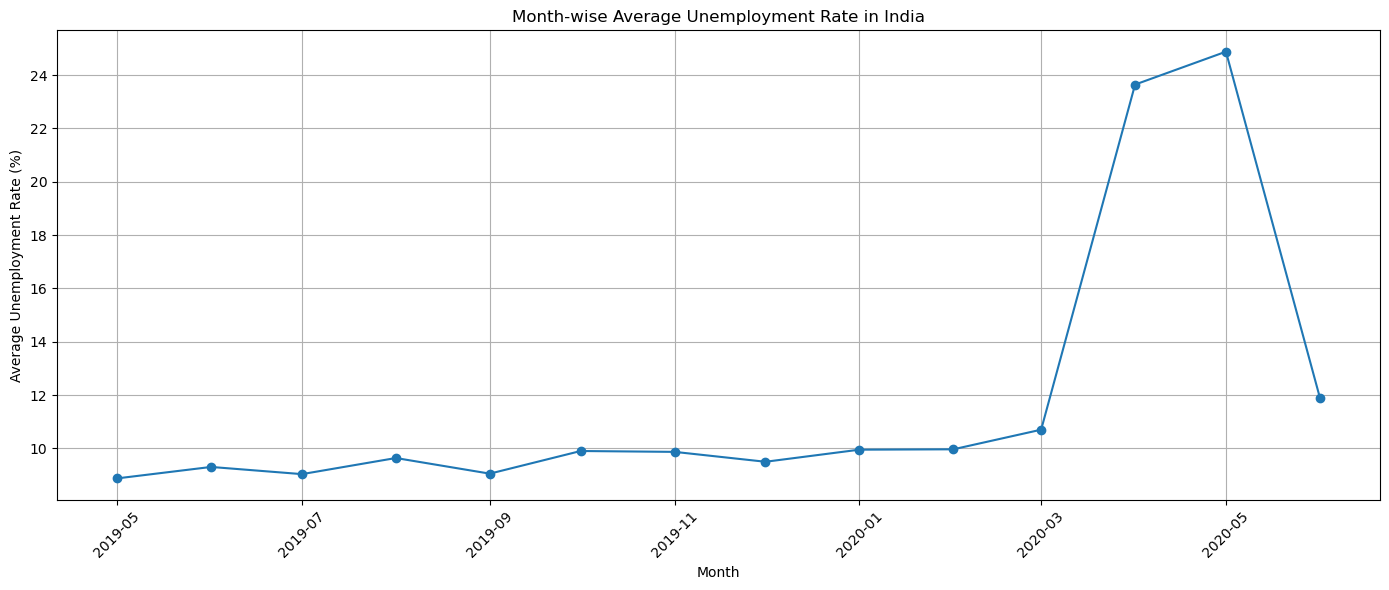

In [28]:
plt.figure(figsize=(14, 6))

plt.plot(
    monthly_avg.index,
    monthly_avg.values,
    marker="o"
)

plt.title("Month-wise Average Unemployment Rate in India")
plt.xlabel("Month")
plt.ylabel("Average Unemployment Rate (%)")
plt.xticks(rotation=45)
plt.grid(True)

plt.tight_layout()
plt.show()

In [29]:
# Time-series line chart
selected_regions = [
    "Tripura",
    "Haryana",
    "Jharkhand"
]

three_regions = df[
    df["Region"].isin(selected_regions)
].copy()

In [30]:
monthly_region = (
    three_regions
    .groupby([
        "Region",
        three_regions["Date"].dt.to_period("M")
    ])["Estimated Unemployment Rate (%)"]
    .mean()
    .reset_index()
)

monthly_region["Date"] = monthly_region["Date"].dt.to_timestamp()

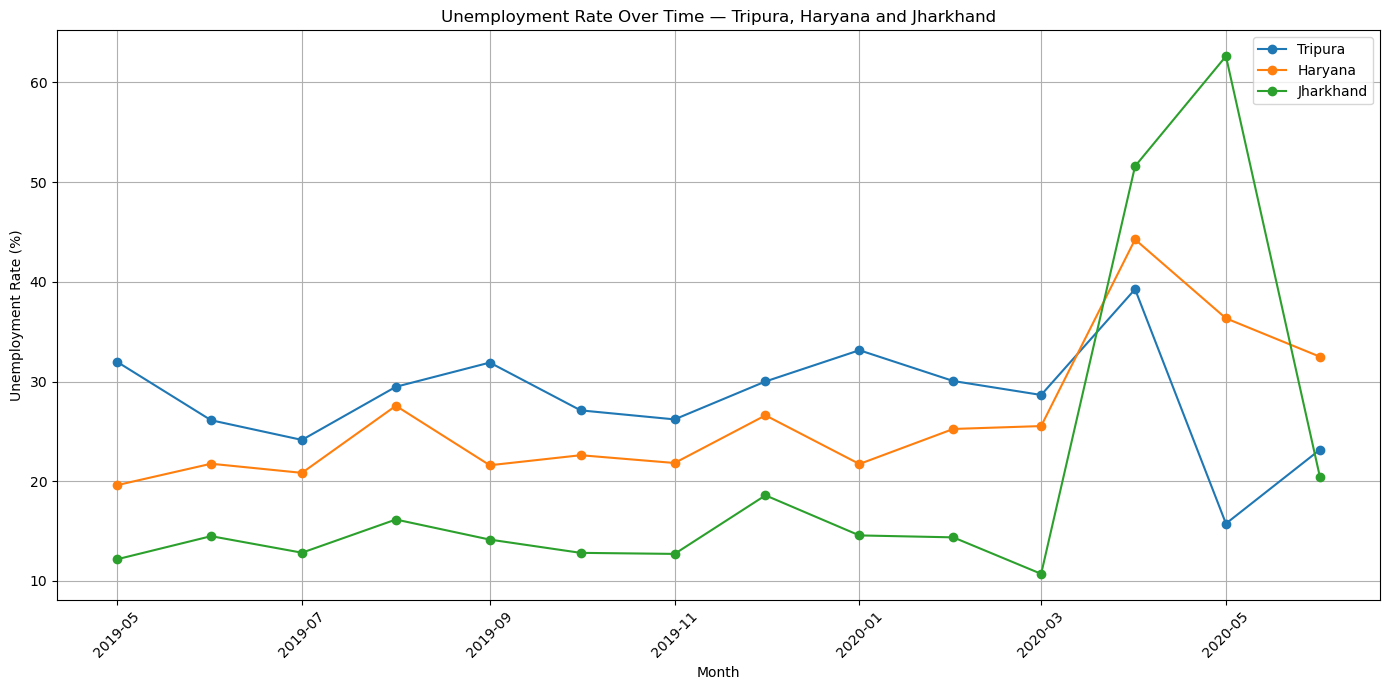

In [32]:
plt.figure(figsize=(14, 7))

for region in selected_regions:
    region_data = monthly_region[
        monthly_region["Region"] == region
    ]

    plt.plot(
        region_data["Date"],
        region_data["Estimated Unemployment Rate (%)"],
        marker="o",
        label=region
    )

plt.title("Unemployment Rate Over Time — Tripura, Haryana and Jharkhand")
plt.xlabel("Month")
plt.ylabel("Unemployment Rate (%)")

plt.legend()
plt.grid(True)
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

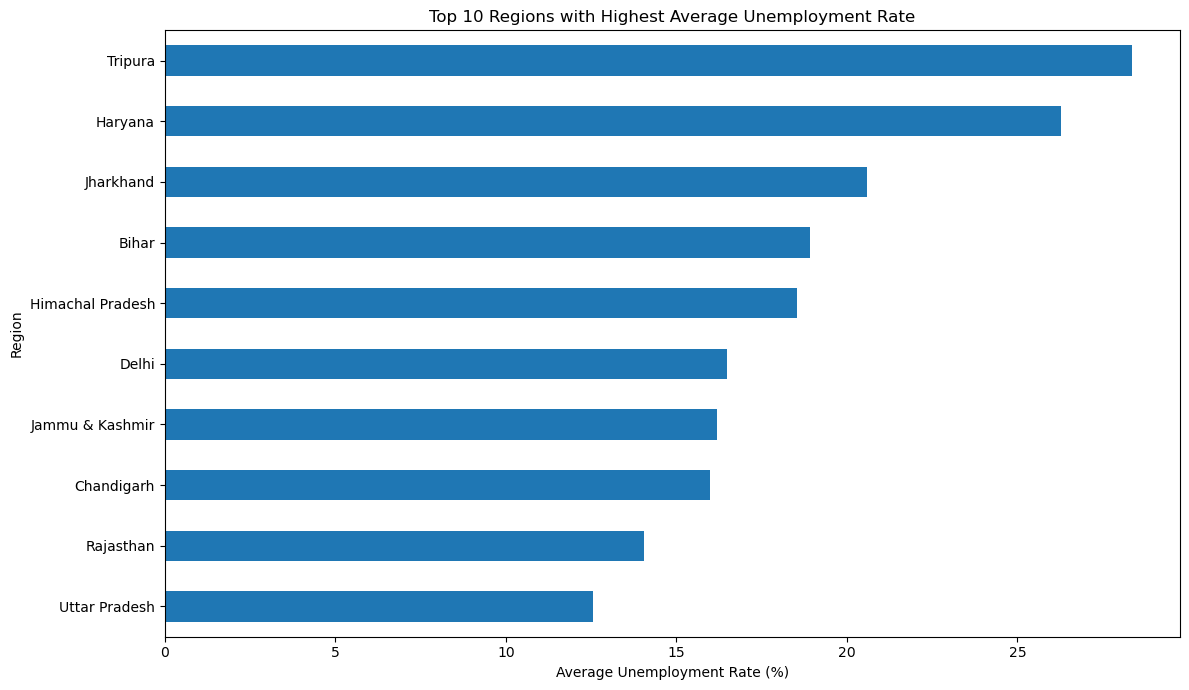

In [33]:
# Top 10 states with highest average unemployment rate
plt.figure(figsize=(12, 7))

top_10.sort_values().plot(kind="barh")

plt.title("Top 10 Regions with Highest Average Unemployment Rate")
plt.xlabel("Average Unemployment Rate (%)")
plt.ylabel("Region")

plt.tight_layout()
plt.show()

In [34]:
# Heatmap: Correlation matrix
correlation = df[
    [
        "Estimated Unemployment Rate (%)",
        "Estimated Employed",
        "Estimated Labour Participation Rate (%)"
    ]
].corr()

correlation

,Estimated Unemployment Rate (%),Estimated Employed,Estimated Labour Participation Rate (%)
Estimated Unemployment Rate (%),1.000000,-0.222876,0.002558
Estimated Employed,-0.222876,1.000000,0.011300
Estimated Labour Participation Rate (%),0.002558,0.011300,1.000000


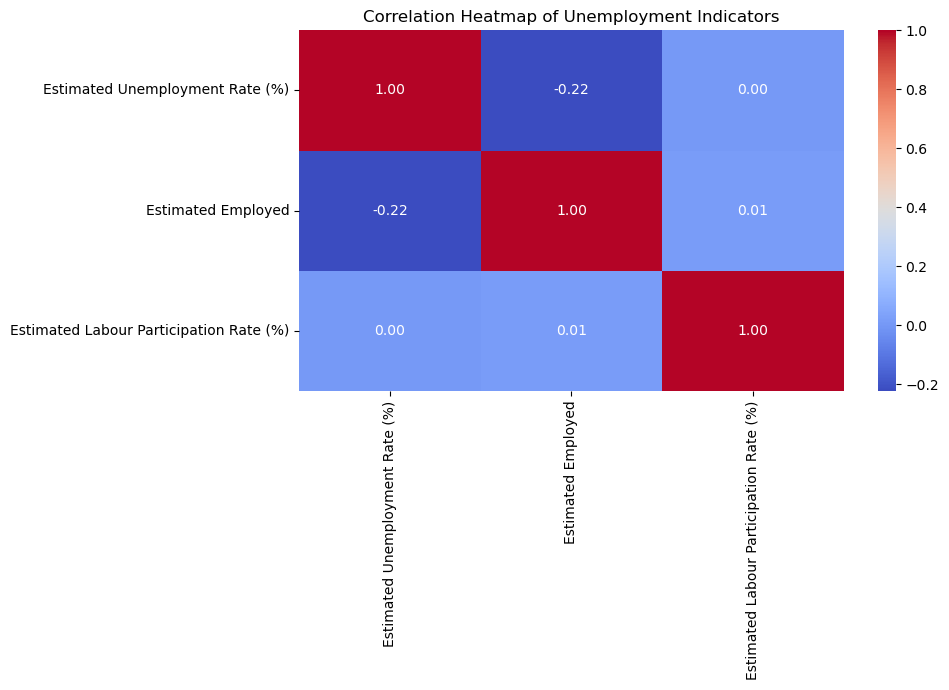

In [35]:
# Heatmap
plt.figure(figsize=(10, 7))

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Heatmap of Unemployment Indicators")
plt.tight_layout()
plt.show()

Pre-COVID vs. post-COVID comparison 


In [36]:
# Data split
pre_covid = df[
    df["Date"] < "2020-03-01"
].copy()

post_covid = df[
    df["Date"] >= "2020-03-01"
].copy()

In [37]:
# periods average
pre_covid_avg = pre_covid[
    "Estimated Unemployment Rate (%)"
].mean()

post_covid_avg = post_covid[
    "Estimated Unemployment Rate (%)"
].mean()

print("Pre-COVID Average Unemployment Rate:",
      round(pre_covid_avg, 2), "%")

print("Post-COVID Average Unemployment Rate:",
      round(post_covid_avg, 2), "%")

Pre-COVID Average Unemployment Rate: 9.51 %
Post-COVID Average Unemployment Rate: 17.77 %


In [38]:
#: Difference calculation
difference = post_covid_avg - pre_covid_avg

print("Difference:",
      round(difference, 2), "percentage points")

Difference: 8.26 percentage points


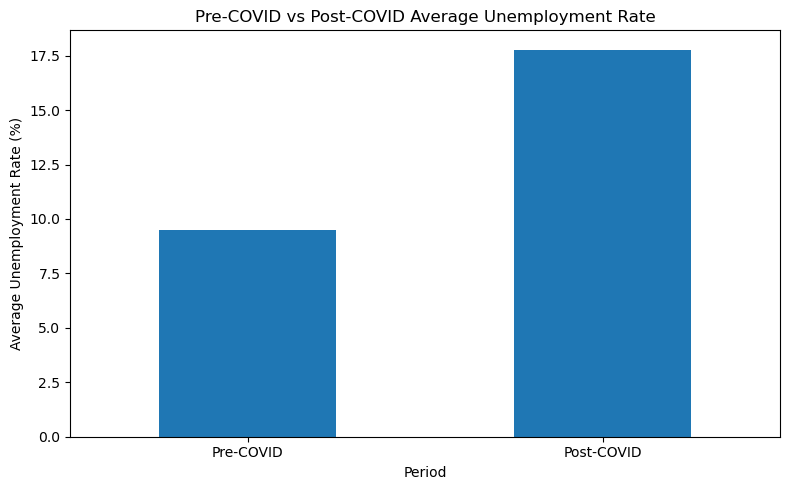

In [39]:
# Comparison ko chart
covid_comparison = pd.Series({
    "Pre-COVID": pre_covid_avg,
    "Post-COVID": post_covid_avg
})

plt.figure(figsize=(8, 5))

covid_comparison.plot(kind="bar")

plt.title("Pre-COVID vs Post-COVID Average Unemployment Rate")
plt.xlabel("Period")
plt.ylabel("Average Unemployment Rate (%)")

plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [ ]:
[ ] Written observations/markdown cells between each chart explaining what the data
shows
● [ ] Clean, well-commented Jupyter Notebook